## Iris Flower Classification Using Supervised Machine Learning

### 1. Project Introduction

#### 1.1 Overview

This project focuses on developing and evaluating supervised machine learning classification models using the Iris dataset. The objective is to predict the species of an Iris flower based on four numerical measurements: sepal length, sepal width, petal length, and petal width.

Two classification algorithms, Logistic Regression and Decision Tree Classifier, will be implemented and compared to understand their predictive performance.

#### 1.2 Problem Statement

Identifying flower species based on physical measurements can be treated as a multiclass classification problem. This project aims to develop machine learning models capable of accurately classifying Iris flowers into one of three species: Setosa, Versicolor, and Virginica.

#### 1.3 Project Objectives

- Explore and understand the Iris dataset.
- Perform exploratory data analysis to identify patterns and relationships among features.
- Prepare the dataset through appropriate preprocessing and feature scaling.
- Split the dataset into training and testing subsets using an 80/20 ratio.
- Train Logistic Regression and Decision Tree classification models.
- Evaluate model performance using accuracy, precision, recall, and F1-score.
- Visualize classification results using confusion matrices and decision boundaries.
- Compare the performance of both algorithms and draw conclusions.

#### 1.4 Dataset Description

The Iris dataset contains 150 observations representing three Iris flower species:

- Iris Setosa
- Iris Versicolor
- Iris Virginica

Each observation contains four numerical input features:

| Feature | Description |
|---|---|
| Sepal Length | Length of the sepal in centimeters |
| Sepal Width | Width of the sepal in centimeters |
| Petal Length | Length of the petal in centimeters |
| Petal Width | Width of the petal in centimeters |

The target variable is `species`, which represents the flower's classification category.

#### 1.5 Expected Outcomes

By the end of this project, two supervised classification models will be developed and evaluated. Their performance will be compared using standard classification metrics to determine their effectiveness in identifying Iris flower species.

Import Libraries


In [92]:
import pandas as pd
import numpy as np
import matplotlib 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score,precision_score, recall_score, f1_score, confusion_matrix, classification_report

Load the dataset


In [93]:
df = pd.read_csv('../Multiclass_Benchmark_Classification_Pipeline/data/iris.csv')

Inspect the dataset

In [94]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [95]:
df.shape

(150, 5)

In [96]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [97]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [98]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


Data Cleaning and Preprocessing

In [99]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

There is no null values in the dataset.

In [100]:
df.duplicated().sum()

np.int64(1)

There is one duplicate, so we will drop the duplicated row.

In [101]:
df = df.drop_duplicates()

In [102]:
df.duplicated().sum()

np.int64(0)

EDA

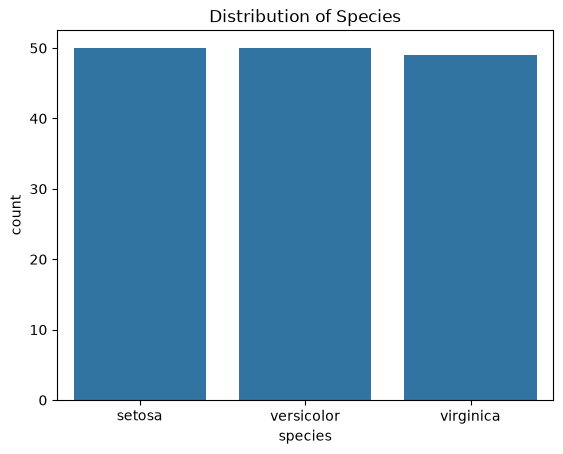

In [103]:
# Species Distribution
sns.countplot(x = 'species', data = df)
plt.title('Distribution of Species')
plt.show()

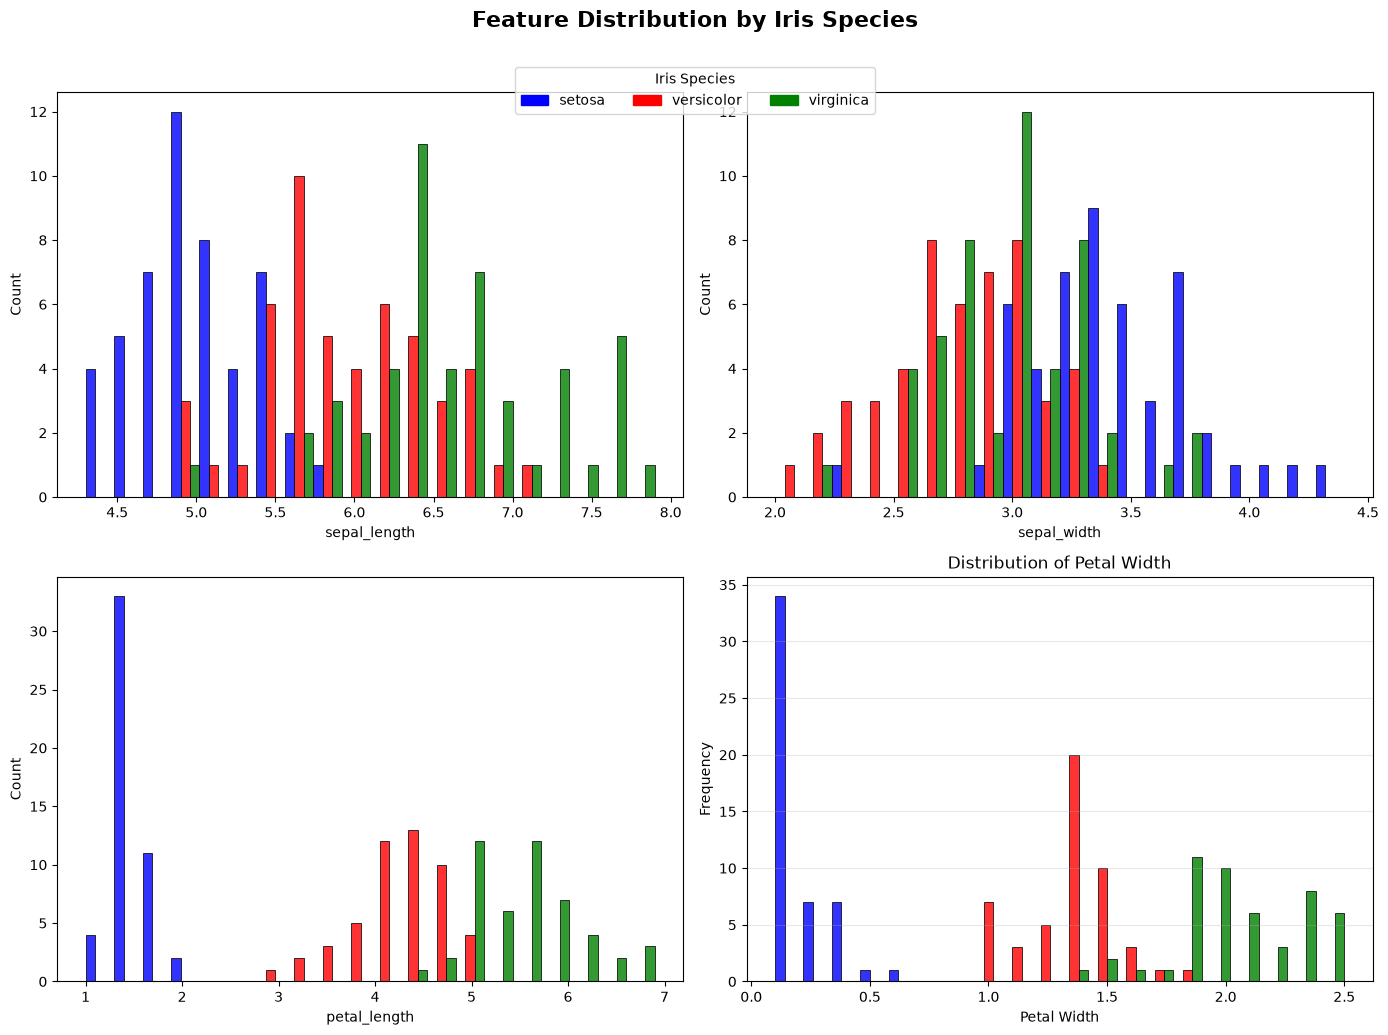

In [104]:
# Feature Distribution
color_palette = {
    'setosa' : 'blue',
    'versicolor' : 'red',
    'virginica' : 'green'
}

features =  ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

fig , axes = plt.subplots(2, 2, figsize = (14,10))

axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.histplot(
        data = df,
        x = feature,
        hue =  'species',
        palette = color_palette,
        multiple="dodge",
        alpha=0.8,
        bins=20,
        ax=ax,
        legend=False
    )

ax.set_title(f"Distribution of {feature.replace('_', ' ').title()}")
ax.set_xlabel(feature.replace("_", " ").title())
ax.set_ylabel("Frequency")
ax.grid(axis="y", alpha=0.3)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=color)
    for color in color_palette.values()
]

fig.legend(
    handles,
    color_palette.keys(),
    title="Iris Species",
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.98)
)

fig.suptitle(
    'Feature Distribution by Iris Species',
    fontsize = 16,
    fontweight = 'bold',
    y = 1.03
)

plt.tight_layout()
plt.show()

- Virginica has the longest sepal and wider as well as longer petal compared to the other species.

- The sepal and petal length and width is moderate for the Versicolor species.

- Most of the Setosa species have a shorter petal and sepal. Despite the width of their petal being low, Setosa has a wider sepal.

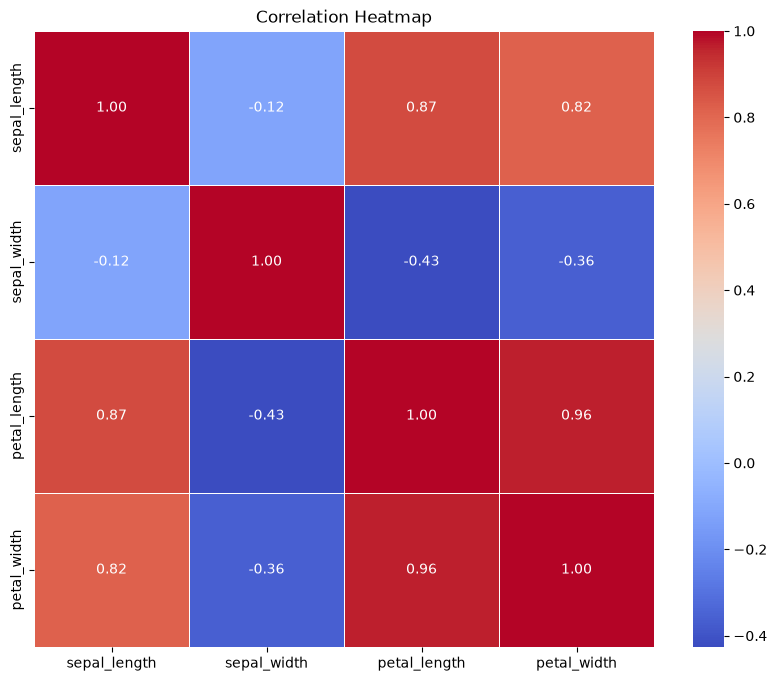

In [105]:
# Correlation Heatmap
corr_matrix = df.corr(numeric_only = True)
plt.figure(figsize = (10, 8))

sns.heatmap(
    corr_matrix, 
    annot=True,      
    cmap='coolwarm', 
    fmt='.2f',       
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()


- There is a strong correlation between the species petal length and width. On the other hand, 

there is barely a relationship between the length and width of the sepal. The length of the petal 

and sepal has a stronger correlation than their width.

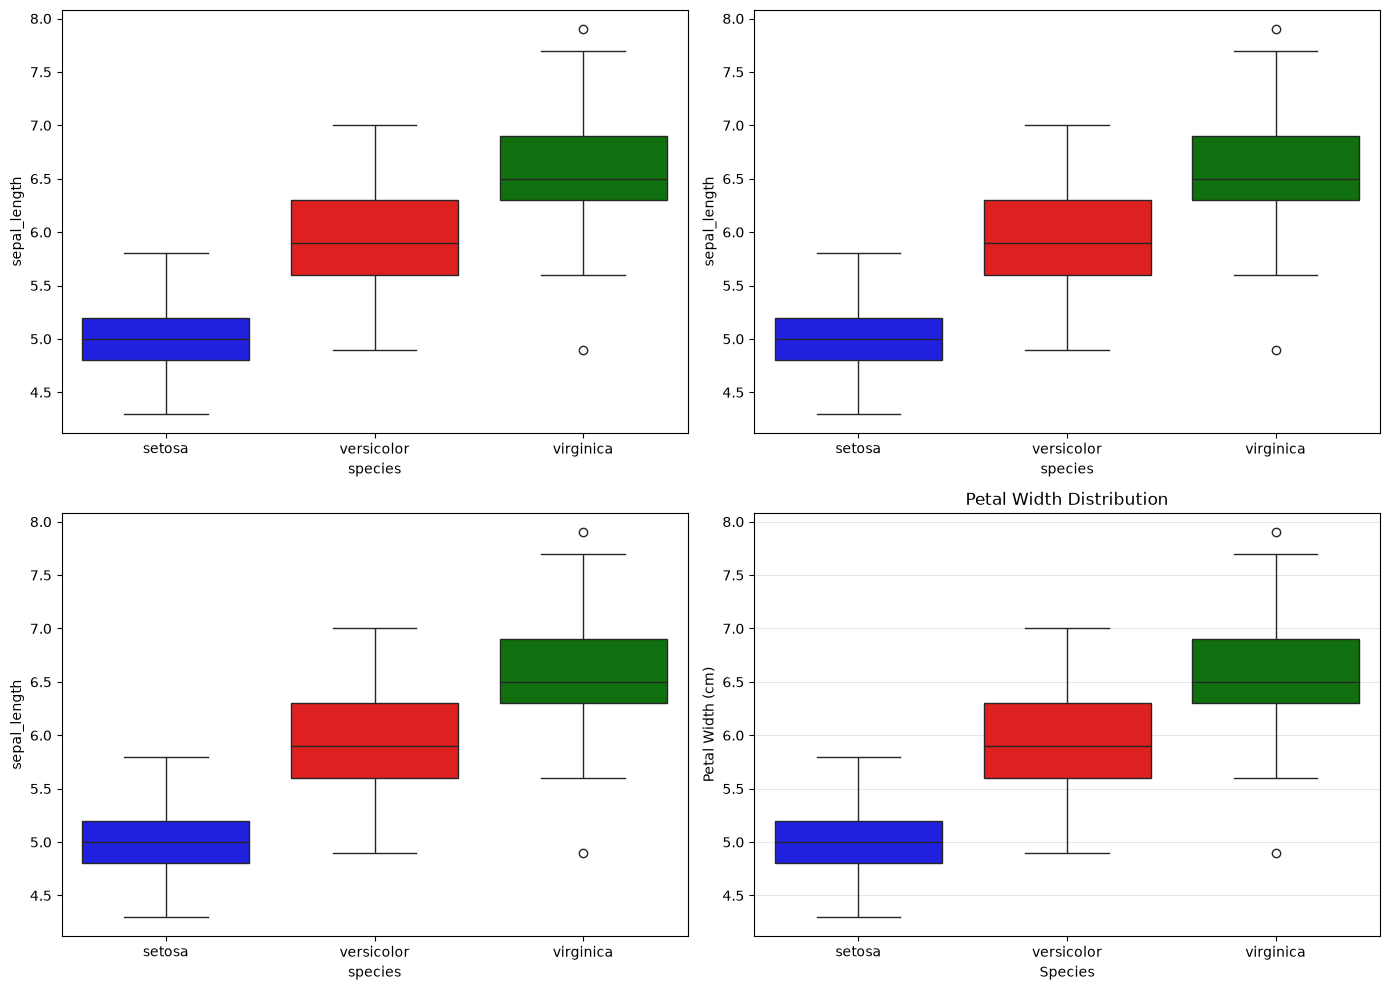

In [106]:
# BoxPlot - Outlier Detection
features =  ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

fig, axes = plt.subplots(2, 2, figsize = (14,10))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x='species',
        y='sepal_length',
        hue='species',
        palette=color_palette,
        legend=False,
        ax=ax
    )

ax.set_title(f'{feature.replace("_", " ").title()} Distribution')
ax.set_xlabel('Species')
ax.set_ylabel(f'{feature.replace("_", " ").title()} (cm)')

ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- Virginica is the only species that has minimal outliers amongst the four features.

Dataset Splitting and Feature Scaling

In [107]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[features]
y = df['species']


In [108]:
X_train, X_test , y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

In [109]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Model Development

In [110]:
# Logistic Regression
lr = LogisticRegression()

lr.fit(X_train, y_train)

test_predictions = lr.predict(X_test)

lr_accuracy = accuracy_score(y_test, test_predictions)
lr_precision = precision_score(y_test, test_predictions, average='weighted')
lr_recall = recall_score(y_test, test_predictions, average='weighted')
lr_f1 = f1_score(y_test, test_predictions, average='weighted')
lr_cm = confusion_matrix(y_test, test_predictions)

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")

print("\nConfusion Matrix")
print(lr_cm)

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000

Confusion Matrix
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [111]:
# Decision Tree Classifier
dt = DecisionTreeClassifier()

dt.fit(X_train, y_train)

test_predictions = dt.predict(X_test)

dt_accuracy = accuracy_score(y_test, test_predictions)
dt_precision = precision_score(y_test, test_predictions, average='weighted')
dt_recall = recall_score(y_test, test_predictions, average='weighted')
dt_f1 = f1_score(y_test, test_predictions, average='weighted')
dt_cm = confusion_matrix(y_test, test_predictions)

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")

print("\nConfusion Matrix")
print(dt_cm)

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000

Confusion Matrix
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


- Both models have the same accuracy, precision, f1_score and recall.